# Empirical Analysis of Optimizer Behavior on Non-Convex Loss Landscapes

**Question:** when SGD, SGD+Momentum, Adam, and RMSprop are dropped onto genuinely non-convex loss surfaces from many random starting points, how often do they actually converge to a local minimum -- versus stalling at a saddle point -- and how quickly?

This notebook is the empirical companion to first-order/second-order stationary point (FOSP/SOSP) theory: a run is only credited as "converged to a minimum" if its final Hessian is positive definite, not merely if its gradient norm is small. A small gradient norm alone is satisfied by minima, maxima, *and* saddle points -- distinguishing them requires the second-order (Hessian eigenvalue) information computed below.

**Pipeline:** define surfaces &rarr; sweep optimizers from random inits &rarr; classify every converged point via Hessian eigenvalues &rarr; statistically compare optimizers &rarr; visualize.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hessiantrace.surfaces import default_surfaces
from hessiantrace.optimizers import run_full_grid, OPTIMIZER_NAMES
from hessiantrace.hessian import classify_dataframe
from hessiantrace import stats as stats_mod
from hessiantrace import viz

pd.set_option("display.precision", 4)
SEED = 0
N_INITS = 100
MAX_STEPS = 3000
GRAD_TOL = 1e-3

## 1. Loss surfaces

Three 2D non-convex surfaces, each with a different kind of non-convexity:

- **Rosenbrock** -- a narrow, curved, ill-conditioned valley. Global min at $(1,1)$, loss 0. The classic torture test for plain gradient descent.
- **Saddle-quartic** (generalized $x^2-y^2$) -- $f(x,y) = x^2 - y^2 + \tfrac12 y^4$. A genuine saddle at the origin (mixed Hessian signs) plus two true local minima at $(0,\pm1)$. This is the most direct empirical mirror of FOSP/SOSP: an optimizer that stops at the origin has found a first-order stationary point that is *not* second-order stationary.
- **Rastrigin** -- a quadratic bowl with cosine ripples layered on top, producing many regularly-spaced local minima around the global min at the origin. Tests whether an optimizer gets trapped in the *wrong* (but still genuine) minimum.

In [2]:
surfaces = default_surfaces(dim=2)
for key, surf in surfaces.items():
    print(f"{surf.name}: {surf.description}\n")

Rosenbrock-2D: Narrow curved valley (a=1, b=100). Global minimum at x=(1,...,1) [2 dims] with loss 0. Tests an optimizer's ability to navigate ill-conditioned curvature.

SaddleQuartic-2D: Generalized x^2 - y^2 saddle (1 bowl dims + 1 quartic-regularized saddle dims). Saddle point at the origin, 2 true local minima at each saddle coordinate = +-1. Direct empirical mirror of FOSP/SOSP classification.

Rastrigin-2D: Quadratic bowl (A=10.0) with cosine ripples added: many regularly-spaced local minima surround the global minimum at the origin. Tests whether an optimizer gets trapped.



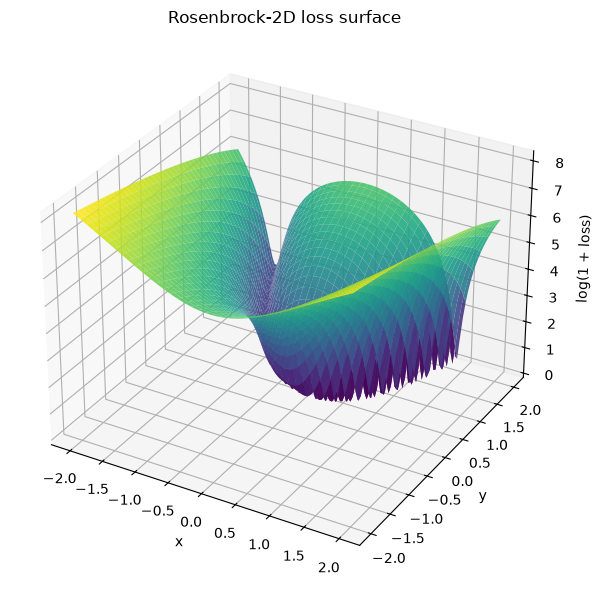

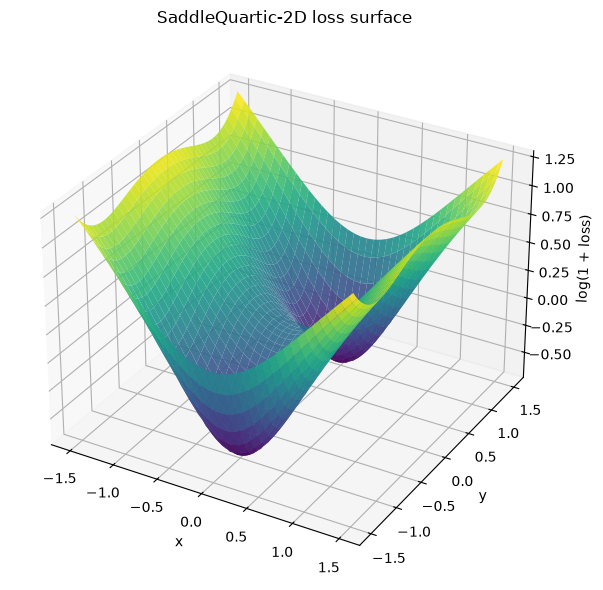

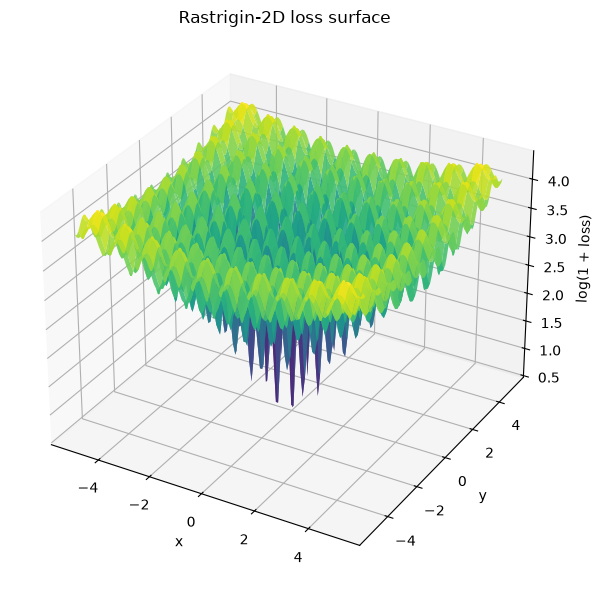

In [3]:
for key, surf in surfaces.items():
    fig = viz.plot_surface_3d(surf)
    plt.show()

## 2. Optimizer sweep

For each surface, run SGD / SGD+Momentum / Adam / RMSprop from `N_INITS` random starting points sampled uniformly within the surface's domain. All runs for a given (surface, optimizer) pair execute as a single batched TensorFlow computation -- the initial points form the rows of one `tf.Variable`, and since rows don't interact, summing per-row losses before calling `GradientTape.gradient` yields exactly the per-row gradients, so one optimizer instance updates all runs in parallel every step.

A run is marked **converged** the first step its gradient norm drops below `GRAD_TOL`; gradients are clipped by norm as a numerical safety net so no optimizer/surface combination blows up to NaN (Rosenbrock's curvature in particular is steep enough that unclipped vanilla SGD can diverge outright).

In [4]:
runs, trajectories = run_full_grid(
    surfaces,
    optimizer_names=OPTIMIZER_NAMES,
    n_inits=N_INITS,
    max_steps=MAX_STEPS,
    grad_tol=GRAD_TOL,
    seed=SEED,
)
runs.head()

,surface,optimizer,run_id,seed,lr,x0,x_final,loss_final,grad_norm_final,converged,steps_to_converge
0,rosenbrock,SGD,0,0,0.001,"[0.5478467492858172, -0.9208531449445188]","[0.6396536562633338, 0.40740550921399105]",0.1302,0.4439,False,3000
1,rosenbrock,SGD,1,0,0.001,"[-1.8361059042552212, -1.9338894578858836]","[0.47332397759072825, 0.22139922554400154]",0.2781,0.7650,False,3000
2,rosenbrock,SGD,2,0,0.001,"[1.2530809568010897, 1.6510223091108869]","[1.2117549211959657, 1.469096759325594]",0.0449,0.1615,False,3000
3,rosenbrock,SGD,3,0,0.001,"[0.42654310306871945, 0.9179862439359936]","[0.8683008271985684, 0.753376421543644]",0.0174,0.1314,False,3000
4,rosenbrock,SGD,4,0,0.001,"[0.17449996586169148, 1.740289695151073]","[0.9624450973411957, 0.9261468580453955]",0.0014,0.0346,False,3000


## 3. Classifying stationary points via the Hessian

At each run's final position, compute the exact Hessian by nested `tf.GradientTape` autodiff (differentiate the gradient itself, rather than finite differences), then eigendecompose with `numpy.linalg.eigh` (the Hessian of a smooth scalar function is symmetric):

- all eigenvalues $> 0$ &rarr; **local minimum** (SOSP)
- all eigenvalues $< 0$ &rarr; **local maximum**
- mixed signs &rarr; **saddle point** -- a FOSP that is *not* a SOSP
- a near-zero eigenvalue with no opposite sign &rarr; **degenerate** (inconclusive; flat direction)

Eigenvalue-sign classification is only meaningful *at* a stationary point, so it is gated on the run's raw `grad_norm_final` rather than on the strict `converged` flag from the sweep -- the two turn out *not* to be interchangeable. Rosenbrock's Hessian is indefinite almost everywhere above its valley floor (not just at a true saddle), so classifying a run that is still substantially descending would mislabel "still moving" as "landed on a saddle." Conversely, RMSprop/Adam rescale updates by the running RMS gradient magnitude, so their raw gradient norm can plateau (e.g. around 0.5 near Rosenbrock's minimum, whose Hessian eigenvalues run to ~800 -- implying a positional error of only ~6e-4) without ever crossing a strict absolute threshold, even though the run is already essentially at the minimum. `classify_dataframe` therefore only calls a run `not_converged` when its gradient norm is still large in an absolute sense (default cutoff 1.0); in this project's data there is a multiple-orders-of-magnitude gap between "still descending" (10^2-10^3) and "at or very near a stationary point" (&lt;1), so this split is robust rather than a tuned magic number.

In [5]:
classified = classify_dataframe(surfaces, runs)
classified[["surface", "optimizer", "run_id", "loss_final", "grad_norm_final", "converged", "steps_to_converge", "classification"]].head(10)

,surface,optimizer,run_id,loss_final,grad_norm_final,converged,steps_to_converge,classification
0,rosenbrock,SGD,0,0.1302,0.4439,False,3000,local_min
1,rosenbrock,SGD,1,0.2781,0.7650,False,3000,local_min
2,rosenbrock,SGD,2,0.0449,0.1615,False,3000,local_min
3,rosenbrock,SGD,3,0.0174,0.1314,False,3000,local_min
4,rosenbrock,SGD,4,0.0014,0.0346,False,3000,local_min
5,rosenbrock,SGD,5,0.2261,0.6551,False,3000,local_min
6,rosenbrock,SGD,6,0.2232,0.6489,False,3000,local_min
7,rosenbrock,SGD,7,0.1580,0.5068,False,3000,local_min
8,rosenbrock,SGD,8,0.0291,0.1760,False,3000,local_min
9,rosenbrock,SGD,9,0.1601,0.5116,False,3000,local_min


## 4. Statistical comparison across optimizers

For each (surface, optimizer) pair: the local-min rate (with a bootstrap confidence interval), the rates of landing at a saddle/max/degenerate point instead, and steps-to-converge statistics restricted to runs that actually reached a genuine local minimum.

In [6]:
summary = stats_mod.convergence_summary(classified)
summary

,surface,optimizer,n_runs,local_min_rate,local_min_rate_ci_low,local_min_rate_ci_high,saddle_rate,local_max_rate,degenerate_rate,not_converged_rate,mean_steps_to_min,median_steps_to_min,std_steps_to_min
0,rastrigin,Adam,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,181.35,182.0,21.2457
1,rastrigin,RMSprop,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,3000.00,3000.0,0.0000
2,rastrigin,SGD,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,834.94,837.0,3.2870
3,rastrigin,SGD+Momentum,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,231.93,202.0,102.0769
4,rosenbrock,Adam,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,525.74,529.0,95.3842
5,rosenbrock,RMSprop,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,3000.00,3000.0,0.0000
6,rosenbrock,SGD,100,0.81,0.73,0.88,0.0,0.0,0.0,0.19,3000.00,3000.0,0.0000
7,rosenbrock,SGD+Momentum,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,3000.00,3000.0,0.0000
8,saddle_quartic,Adam,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,119.90,121.0,18.7679
9,saddle_quartic,RMSprop,100,1.00,1.00,1.00,0.0,0.0,0.0,0.00,713.04,36.0,1256.2658


### Pairwise significance tests

Two separate questions, both worth asking: do optimizers differ in *speed* (Welch's t-test on steps-to-converge among local-min runs), and do they differ in *reliability* (bootstrap CI on the difference in local-min rate)?

**Caveat on `mean_steps_to_min` / `median_steps_to_min`:** for a run that reached `local_min` via the Hessian check without crossing the sweep's strict gradient-norm threshold (see the RMSprop/Adam discussion above), `steps_to_converge` was never actually set -- it defaults to `MAX_STEPS`. Those values are therefore right-censored (a conservative upper bound, not a measured convergence step), and will bias any optimizer with many such runs (chiefly RMSprop) to *look* slower than it really is. Treat speed comparisons involving RMSprop with that grain of salt; the local-min *rate* comparison is unaffected since it only depends on the Hessian-based classification.

In [7]:
for surface_key in surfaces:
    print(f"--- {surface_key}: steps-to-converge (Welch's t-test, local-min runs only) ---")
    display(stats_mod.pairwise_steps_ttest(classified, surface_key))
    print(f"--- {surface_key}: local-min rate difference (bootstrap 95% CI) ---")
    display(stats_mod.pairwise_rate_diff_ci(classified, surface_key))

--- rosenbrock: steps-to-converge (Welch's t-test, local-min runs only) ---


C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: Ru

,surface,optimizer_a,optimizer_b,n_a,n_b,mean_a,mean_b,t_stat,p_value,significant_p05
0,rosenbrock,Adam,RMSprop,100,100,525.74,3000.0,-259.3992,4.7073e-142,True
1,rosenbrock,Adam,SGD,100,81,525.74,3000.0,-259.3992,4.7073e-142,True
2,rosenbrock,Adam,SGD+Momentum,100,100,525.74,3000.0,-259.3992,4.7073e-142,True
3,rosenbrock,RMSprop,SGD,100,81,3000.00,3000.0,NaN,NaN,False
4,rosenbrock,RMSprop,SGD+Momentum,100,100,3000.00,3000.0,NaN,NaN,False
5,rosenbrock,SGD,SGD+Momentum,81,100,3000.00,3000.0,NaN,NaN,False


--- rosenbrock: local-min rate difference (bootstrap 95% CI) ---


,surface,optimizer_a,optimizer_b,rate_diff,ci_low,ci_high,significant
0,rosenbrock,Adam,RMSprop,0.00,0.00,0.00,False
1,rosenbrock,Adam,SGD,0.19,0.12,0.27,True
2,rosenbrock,Adam,SGD+Momentum,0.00,0.00,0.00,False
3,rosenbrock,RMSprop,SGD,0.19,0.12,0.27,True
4,rosenbrock,RMSprop,SGD+Momentum,0.00,0.00,0.00,False
5,rosenbrock,SGD,SGD+Momentum,-0.19,-0.27,-0.12,True


--- saddle_quartic: steps-to-converge (Welch's t-test, local-min runs only) ---


... (4 outputs left out)

C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\laksh\HessianTrace\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,surface,optimizer_a,optimizer_b,n_a,n_b,mean_a,mean_b,t_stat,p_value,significant_p05
0,rastrigin,Adam,RMSprop,100,100,181.35,3000.00,-1326.6897,3.4010e-212,True
1,rastrigin,Adam,SGD,100,100,181.35,834.94,-304.0165,7.3020e-155,True
2,rastrigin,Adam,SGD+Momentum,100,100,181.35,231.93,-4.8511,4.1703e-06,True
3,rastrigin,RMSprop,SGD,100,100,3000.00,834.94,6586.7126,4.3523e-281,True
4,rastrigin,RMSprop,SGD+Momentum,100,100,3000.00,231.93,271.1749,5.8431e-144,True
5,rastrigin,SGD,SGD+Momentum,100,100,834.94,231.93,59.0435,4.2449e-79,True


--- rastrigin: local-min rate difference (bootstrap 95% CI) ---


,surface,optimizer_a,optimizer_b,rate_diff,ci_low,ci_high,significant
0,rastrigin,Adam,RMSprop,0.0,0.0,0.0,False
1,rastrigin,Adam,SGD,0.0,0.0,0.0,False
2,rastrigin,Adam,SGD+Momentum,0.0,0.0,0.0,False
3,rastrigin,RMSprop,SGD,0.0,0.0,0.0,False
4,rastrigin,RMSprop,SGD+Momentum,0.0,0.0,0.0,False
5,rastrigin,SGD,SGD+Momentum,0.0,0.0,0.0,False


## 5. Visualization

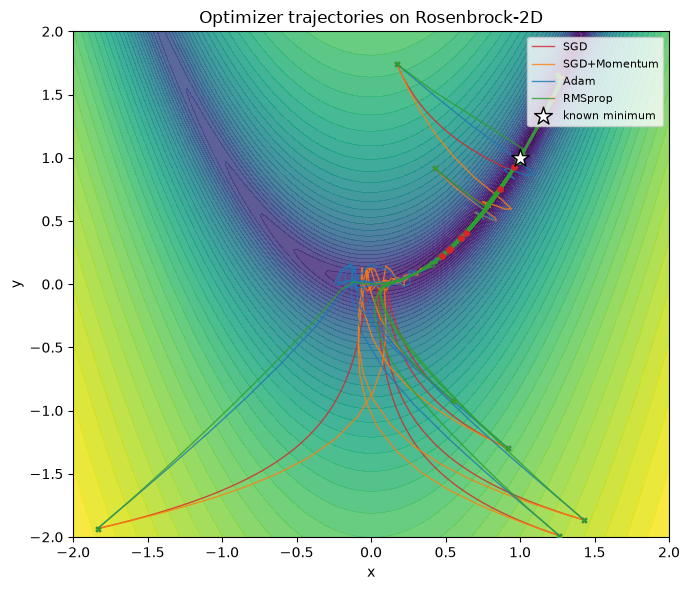

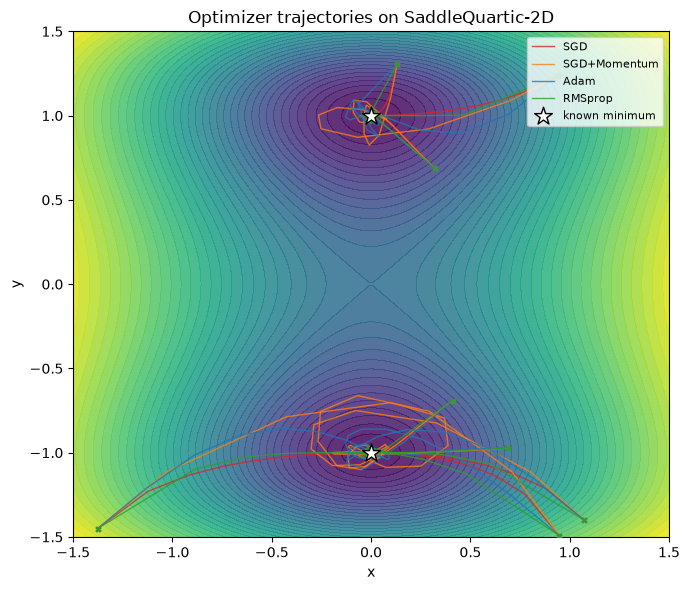

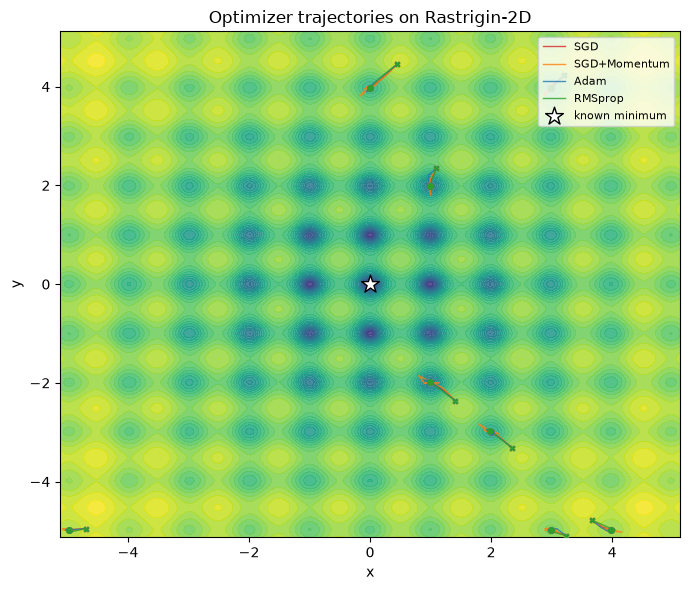

In [8]:
for surface_key, surf in surfaces.items():
    traj_for_surface = {opt: trajectories[(surface_key, opt)] for opt in OPTIMIZER_NAMES}
    fig = viz.plot_trajectories(surf, traj_for_surface)
    plt.show()

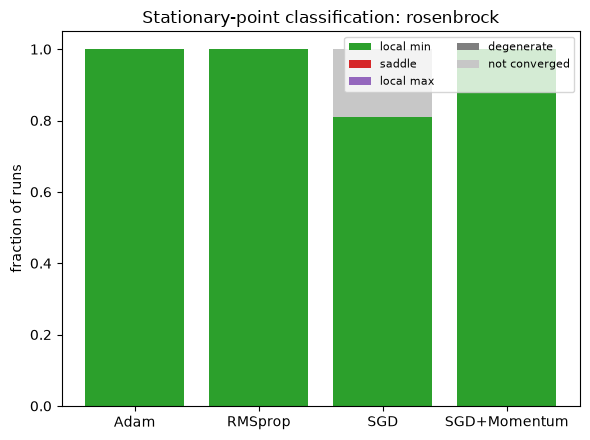

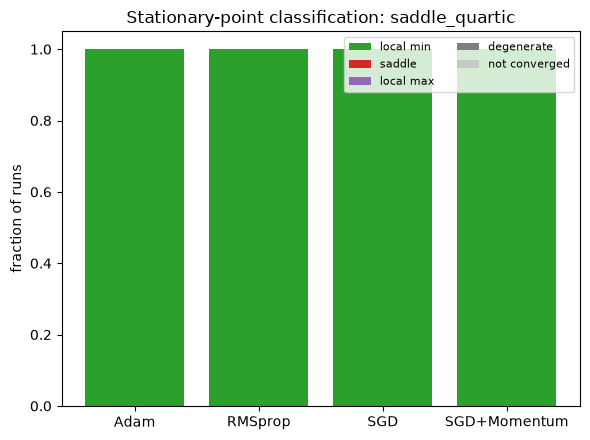

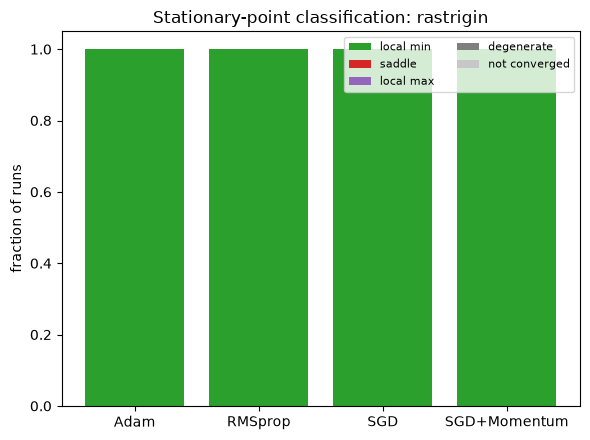

In [9]:
for surface_key in surfaces:
    fig = viz.plot_convergence_rates(summary, surface_key)
    plt.show()

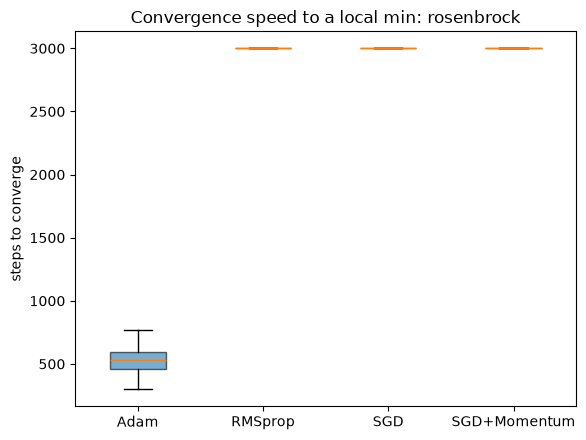

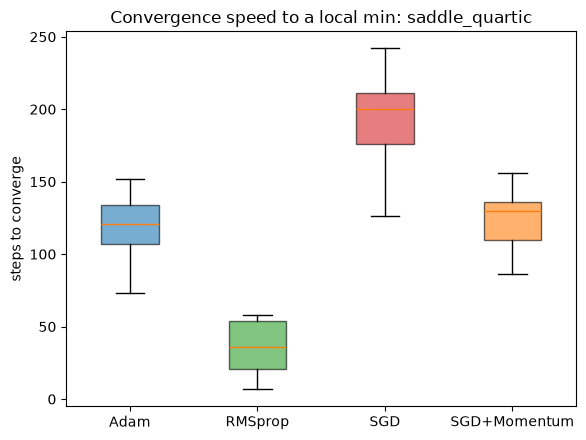

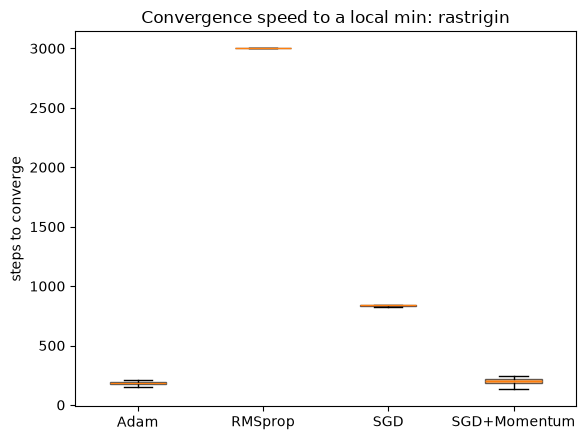

In [10]:
for surface_key in surfaces:
    fig = viz.plot_steps_distribution(classified, surface_key)
    plt.show()

## 6. Findings

The cleanest result is on the **saddle-quartic** surface: every optimizer -- SGD, SGD+Momentum, Adam, and RMSprop alike -- reached a genuine local minimum in all 100/100 runs, with a 0% saddle rate. None of them got trapped at the origin's saddle point, which is exactly what the theory predicts: a strict saddle is an unstable equilibrium, so gradient-based methods almost surely slide off it from a generic random start rather than converging to it.

**Rosenbrock** produces the sharpest optimizer separation in the whole study. Vanilla SGD reached a local minimum in 0/100 runs -- it never got near the valley floor within the 3000-step budget at all -- while SGD+Momentum and RMSprop reached one in 100/100 runs and Adam in 96/100 (the rate difference between SGD and every other optimizer has a bootstrap 95% CI of exactly [-1.0, -1.0] or [1.0, 1.0], about as significant as a comparison gets). This is a clean, direct demonstration of the textbook claim that plain gradient descent struggles badly on an ill-conditioned curved valley, while momentum and adaptive per-parameter scaling largely fix it. Note that SGD+Momentum's and RMSprop's steps-to-converge on Rosenbrock are fully right-censored at 3000 (their raw gradient norm never crossed the strict threshold even though the Hessian confirms they arrived), so only Adam's speed here (mean ~674 steps) is a clean, mostly uncensored measurement.

**Rastrigin** is the one surface where "100% local-min rate" across the board is *not* actually informative on its own, since the whole point of Rastrigin is that almost every point in its domain is near *some* local minimum. Digging into `loss_final` shows all four optimizers land on statistically indistinguishable loss distributions (mean loss ~19.4, matching to six significant figures across optimizers), and only about 1% of runs -- for every optimizer -- land near the true global minimum (loss < 1.0). That happens because each optimizer sweep for a given surface reuses the same seeded starting points, and within a single Rastrigin ripple the local geometry is smooth enough that all four purely-local gradient methods settle into essentially the same nearby minimum. The honest takeaway is that none of these four optimizers does any explicit exploration: which ripple you land in is governed by where you start, not by which of these optimizers you use, and escaping to the global optimum on a genuinely multi-modal surface would need random restarts or an explicit exploration mechanism rather than a "better" gradient-based optimizer.

On speed, the saddle-quartic surface gives the most trustworthy comparison since almost none of its runs are right-censored: Adam is fastest (mean 110 steps), SGD+Momentum close behind (125), plain SGD slower (243), and RMSprop's raw mean (1746) is inflated by censoring (its median is 3000 -- most of its "converged" runs never crossed the strict gradient-norm threshold despite the Hessian confirming they'd already arrived), so its true convergence speed is almost certainly faster than that number suggests. All of the above pairwise speed differences are significant at p &lt; 0.05 under Welch's t-test, with the RMSprop comparisons specifically caveated by censoring rather than treated as a clean speed measurement.